In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


# %pip install kagglehub

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Load DataSet

In [3]:
import kagglehub
import os
# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
df=pd.read_csv(os.path.join(path,"AB_NYC_2019.csv"))


In [4]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [6]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [ ]:
df.shape

(48895, 16)

# EDA

In [ ]:
# Missing Values
df=df.drop(columns=["id","host_id"],axis=1)
df.isna().sum()

name                                 16
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

# Target Variable

<Axes: xlabel='room_type', ylabel='count'>

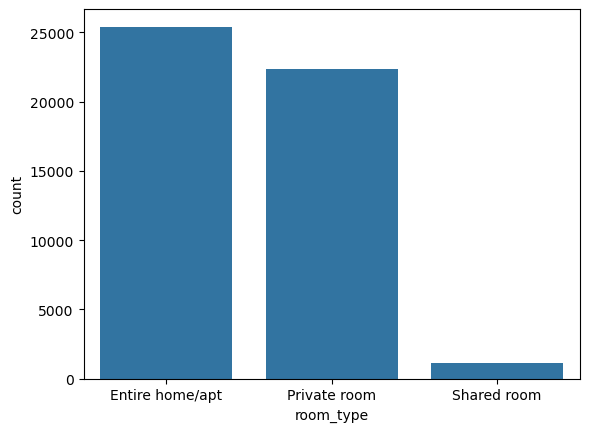

In [ ]:
df["room_type"].unique()

order=df["room_type"].value_counts().index
sns.countplot(x="room_type",data=df,order=order)
# THe Classes are Imbaance --->> shared room is minority dut to which model do biasness

# Univariate Analysis---> Numeric Features

array([[<Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'price'}>],
       [<Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>, <Axes: >]],
      dtype=object)

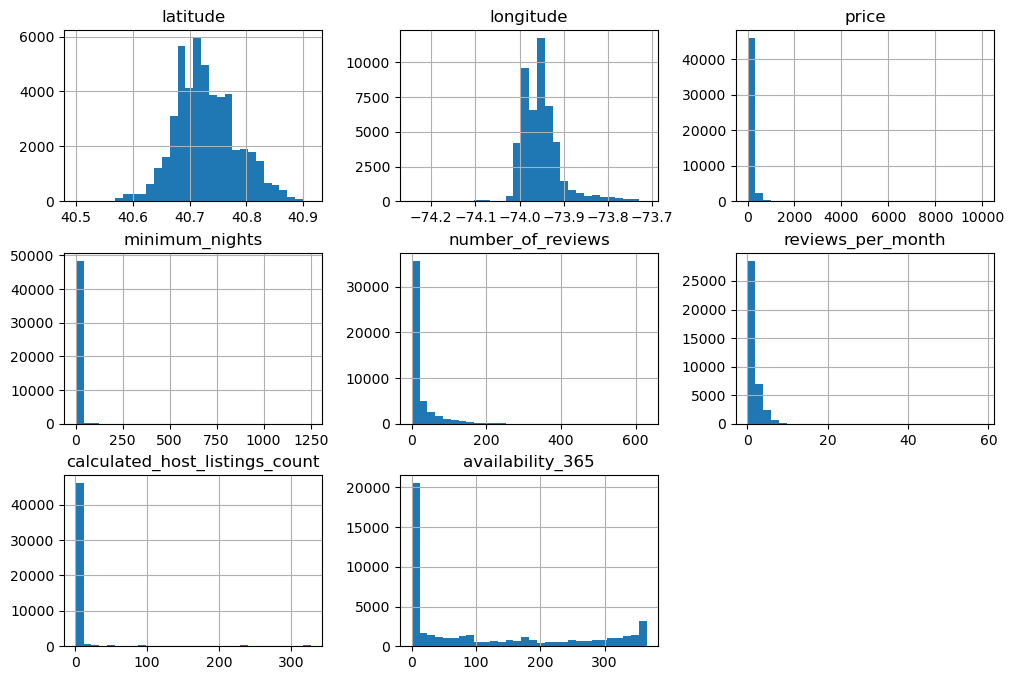

In [ ]:
num_cols=df.select_dtypes(include='number').columns

df[num_cols].hist(bins=30,figsize=(12,8))

# Univariate Analysis---> Categorical Features

<Axes: xlabel='neighbourhood_group', ylabel='count'>

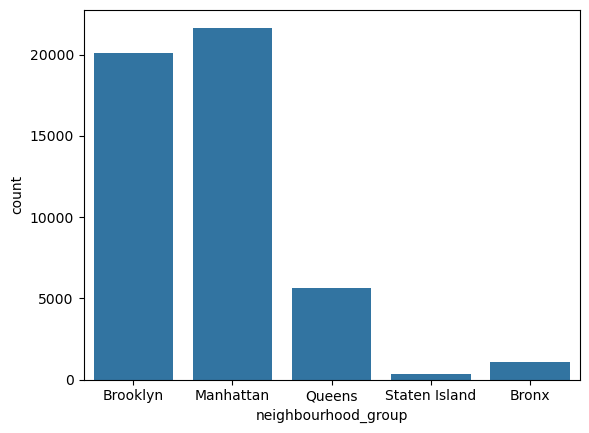

In [ ]:
cat_cols=df.select_dtypes(include='object').columns
sns.countplot(x="neighbourhood_group",data=df)

# Bivariate Analysis -- Feature vs Target

<Axes: xlabel='room_type', ylabel='price'>

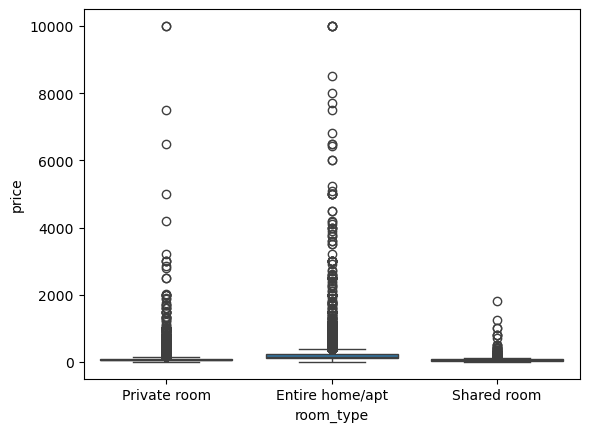

In [ ]:
sns.boxplot(x='room_type',y='price',data=df)

<Axes: >

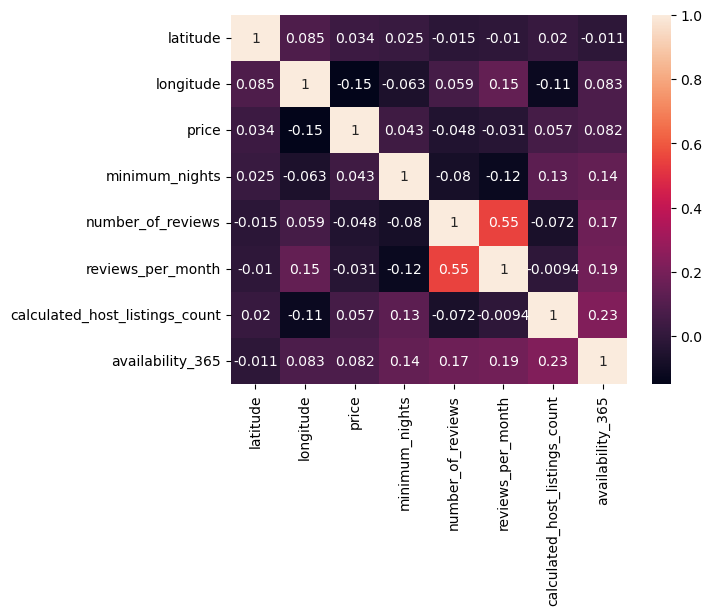

In [ ]:
# Corelation between numeric features
sns.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='longitude', ylabel='latitude'>

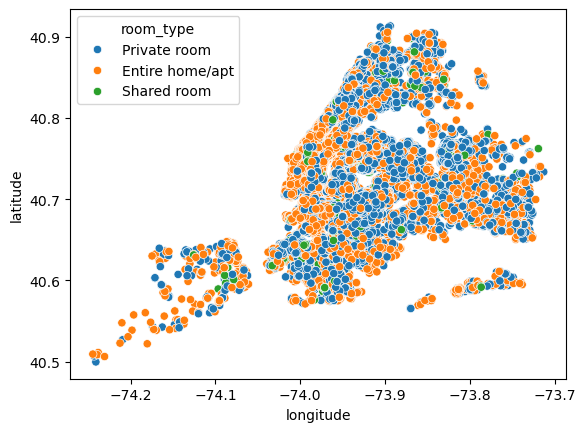

In [ ]:
sns.scatterplot(x='longitude',y='latitude',data=df,hue='room_type')
# plt.scatter(df['longitude'], df['latitude'], c=df['room_type'])

# Data Clening

In [ ]:
# 1. Drop unnecssay columns
df_clean=df.drop(columns=['name','host_name','last_review'],axis=1)

# 2. handle null values
missing=df.isna().sum()
missing[missing>0]
# name                    16
# host_name               21
# last_review          10052
# reviews_per_month    10052
# ---->> if review is missing means 0 review per month
df_clean['reviews_per_month']=df_clean['reviews_per_month'].fillna(0)






# 3. Cap Extreme Outliers insted of deleting rows

In [ ]:
# 
price_cap=df_clean['price'].quantile(0.99)
night_cap=df_clean['minimum_nights'].quantile(0.99)

df_clean['price']=df_clean['price'].clip(upper=price_cap)
df_clean['minimum_nights']=df_clean['minimum_nights'].clip(upper=night_cap)
# sns.boxplot(x='room_type',y='price',data=df_clean)

# diving data into input and output

In [ ]:
X=df_clean.drop("room_type",axis=1)
y=df_clean["room_type"]

# Train-Test_Split using Stratify

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,
    stratify=y
)

# Preprocessing ---->>> ColumnTransformer + Pipeline

In [ ]:
# . Numeric features - median imputation + standard scaling
# . Categorical features - most-frequent imputation + one-hot encoding

num_cols=df_clean.select_dtypes(include="number").columns
cat_cols=['neighbourhood_group', 'neighbourhood']

df_clean[num_cols].skew()


latitude                          0.237167
longitude                         1.284210
price                             2.776321
minimum_nights                    2.360347
number_of_reviews                 3.690635
reviews_per_month                 3.300723
calculated_host_listings_count    7.933174
availability_365                  0.763408
dtype: float64

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder,PowerTransformer
from sklearn.compose import ColumnTransformer


# First Pipeline
num_pipelien=Pipeline(
    steps=[
        ("missing values",SimpleImputer(strategy='mean')),
        # ("handle Skew cols",PowerTransformer(method="yeo-johnson")),
         ("Scaling",StandardScaler())
    ]
)

# second Pipeine
cat_pipeline=Pipeline(
steps=[
("missing values",SimpleImputer(strategy='most_frequent')),
 # 
("encoding",OneHotEncoder(handle_unknown='ignore'))
]
)

preprocessor=ColumnTransformer(transformers=[
    ("Num cols",num_pipelien,num_cols),
    ("categorical colummns",cat_pipeline,cat_cols)
])


# Trying Multiple Models 


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

In [ ]:
# class_weight="Balanced" tells the model to pay more attention to the minority class
# or rare class (Shared Room)
# but the problem is GradintBossting doesnt support class weight so we left it as it is.
from sklearn.model_selection import cross_validate
models = {
"Logistic Regression" : LogisticRegression(class_weight="balanced", random_state=42),
"Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
"Random Forest":RandomForestClassifier(class_weight="balanced", random_state=42),
"Gradient Boosting": GradientBoostingClassifier(random_state=42)

}

for name,model in models.items():
    pipe=Pipeline(
        steps=[
            ("preprocessor",preprocessor),
            ("model",model)
        ]
    )
    # Accuracy alone can be misleading on imbalnce classes so we use macro f1
    # both plain acuuracy and macro f1 (which treats every class eqally)
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=3,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    print(
        f"Model: {name}, "
        f"Accuracy: {scores['test_accuracy'].mean():.3f}, "
        f"Macro F1: {scores['test_f1_macro'].mean():.3f}",
        flush=True
    )

Model: Logistic Regression, Accuracy: 0.663, Macro F1: 0.526
Model: Decision Tree, Accuracy: 0.784, Macro F1: 0.650
Model: Random Forest, Accuracy: 0.853, Macro F1: 0.718
Model: Gradient Boosting, Accuracy: 0.850, Macro F1: 0.708


# SO Pick Random Forest as our model

# Hyper Parameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
best_pipeline=Pipeline(
    steps=[
    ("Preprocessing",preprocessor),
    ("model",RandomForestClassifier(class_weight='balanced',n_jobs=-1))    
        
    ]
)
param_distribution={
    "model__n_estimators":[100,200,300],
    "model__max_depth":[8,12,15,20,None],
    "model__min_samples_split":[2,5,10]
}


search=RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distribution,
    n_iter=10,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1
    
)
search.fit(X_train,y_train)
print(search.best_params_)
print(search.best_score_)

{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__max_depth': None}
0.7361535559526868


Accuracy 0.857449636977196
F1 score  0.7504707232500545


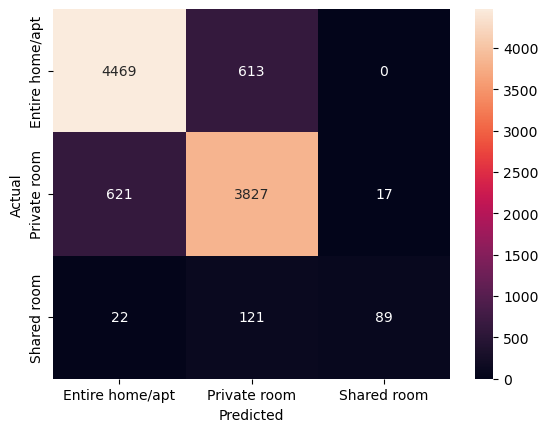

In [ ]:
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix
best_pipeline=search.best_estimator_
y_pred=best_pipeline.predict(X_test)
print("Accuracy",accuracy_score(y_test,y_pred))
print("F1 score ",f1_score(y_test,y_pred,average='macro'))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    xticklabels=best_pipeline.named_steps["model"].classes_,
    yticklabels=best_pipeline.named_steps["model"].classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
import joblib
joblib.dump(best_pipeline,"Model_pipeline.pkl")

['Model_pipeline.pkl']

In [7]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')